# 07. Motor 3 — grafo geométrico, afinidad de saltos y greedy

El Motor 3 resuelve **la misma tarea de despliegue** que los
motores 1 y 2 —un portafolio de $B$ sitios bajo las reglas comunes
del contrato del cuaderno 04— con su propio método: la **afinidad
estructural** de cada sitio al núcleo dorado de estaciones, medida
de forma determinista como $1/(1+\text{saltos a Golden})$ sobre el
grafo geométrico de la red más los sitios candidatos. El Motor 3 es
**autónomo**: no lee salidas de los cuadernos 05 ni 06; sus insumos
son el contrato de despliegue del 04, el entorno de estaciones del
02, las AGEBs del 03 y los viajes del ETL (solo para un diagnóstico
descriptivo).

Tres roles se mantienen separados en todo el cuaderno:

- La **AGEB es contexto**: aporta atributos y población.
- El **sitio —una coordenada de una rejilla— es la unidad de
  decisión**.
- El **portafolio** decide cuántas estaciones recibe cada AGEB: no
  existe restricción de «una por AGEB».

La expansión crece físicamente desde la red: cada sitio seleccionado
queda conectado a la red existente por saltos de a lo sumo la
distancia de enlace. El prescriptor principal es un **greedy de
ganancia marginal** —determinista—; un algoritmo genético sobre
llaves aleatorias se conserva como **sensibilidad** —heurística sin
garantía de óptimo— y se compara contra portafolios aleatorios
decodificados con el mismo constructor de factibilidad.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
from IPython.display import display, Markdown, JSON

BASE = Path.cwd().resolve()
PROJECT = next(p / "4_proyecto" for p in [BASE, *BASE.parents] if (p / "4_proyecto/V3/data").is_dir())
V3_DIR = PROJECT / "V3"
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
from V3.src.m3_analysis import CONFIG, load_inputs, analyze
from V3.src.m3_publication import stage_results

GREEN, GRAY, BLUE, RED, GOLD = "#004731", "#546E7A", "#0D47A1", "#B03A2E", "#B8860B"
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 11})
data = load_inputs(V3_DIR)
result = analyze(data, verbose=True)
report = result["report"]
display(pd.DataFrame([{
    "contract_id": report["contract_id"],
    "analysis_version": report["schema_version"],
    "feature_analysis_id": report["upstream"]["feature_analysis_id"],
    "eda_analysis_id": report["upstream"]["eda_analysis_id"],
    "validation_analysis_id":
        report["upstream"]["validation_analysis_id"],
    "no_motor1_motor2_inputs":
        report["upstream"]["motor1_motor2_not_inputs"],
}]))

[m3] deployment_ctx: 0.3s


[m3] graph+hops: 0.4s


[m3] affinity: 0.4s


[m3] flow: 119.4s


[m3] opt w=0.0 B=30: 119.4s


...

[m3] opt w=0.5 B=50: 812.1s


[m3] opt w=0.75 B=30: 1080.0s


[m3] opt w=1.0 B=30: 1255.3s


[m3] optimize: 1434.8s


,contract_id,analysis_version,feature_analysis_id,eda_analysis_id,validation_analysis_id,no_motor1_motor2_inputs
0,6e586b3d9a0bd8b844d9cf5bc714f0e583fc2a6936f8cd...,v3-motor3-4,7565adda3bc4eb91514247d2a1213f0b1c934821e762ac...,d77ab12f05e9025f438921b34e8688e1a7562826296427...,ed7bf47bafab10ca2b3144e9d38f1d06e5024ee9ba6af3...,True


## 1. Contrato de despliegue (cuaderno 04)

Sitios, celdas de población, reglas de red y métricas provienen
**verificados byte a byte** de la publicación del cuaderno 04; el
arnés comprueba que las funciones de factibilidad y las métricas
usadas aquí son exactamente las del contrato. Los tres motores
comparten la misma malla de presupuestos fijada por el usuario.

In [2]:
sites, stations, cells = (result["sites"], result["stations"],
                          result["cells"])
display(pd.DataFrame([{
    "n_sitios": len(sites),
    "n_agebs_con_sitios": sites.cvegeo.nunique(),
    "n_estaciones": len(stations),
    "link_distance_m": CONFIG["link_distance_m"],
    "min_spacing_m": CONFIG["min_spacing_m"],
    "coverage_radius_m": CONFIG["coverage_radius_m"],
    "malla_presupuestos": str(CONFIG["budget_sensitivity"]),
    "presupuesto_primario": CONFIG["budget"],
    "poblacion_celdas_total": float(cells["pop"].sum()),
    "poblacion_descubierta":
        float(cells.loc[~cells.covered_existing, "pop"].sum()),
}]))

,n_sitios,n_agebs_con_sitios,n_estaciones,link_distance_m,min_spacing_m,coverage_radius_m,malla_presupuestos,presupuesto_primario,poblacion_celdas_total,poblacion_descubierta
0,1656,446,677,500,300,500,"[15, 30, 50]",30,9138388.0,7.968089e+06


## 2. Diagnóstico del grafo de flujos (descriptivo)

Con los viajes verificados del ETL se construye el grafo OD
ponderado entre estaciones existentes, replicando el mapeo del ETL
—los códigos compuestos reparten peso entre sus componentes—. Las
comunidades de Louvain caracterizan el núcleo de flujo y la
«comunidad dorada». Este diagnóstico es **puramente descriptivo**:
no entra al optimizador.

,valor
rows_used,20133540
mapped_weight_share,1.0
self_loop_weight,579412.0
n_communities,4
modularity,0.420677
golden_community,2
golden_community_share,0.45098
golden_intra_median_m,1883.874311
lcc_size,677
embedding_geo_spearman,0.667474


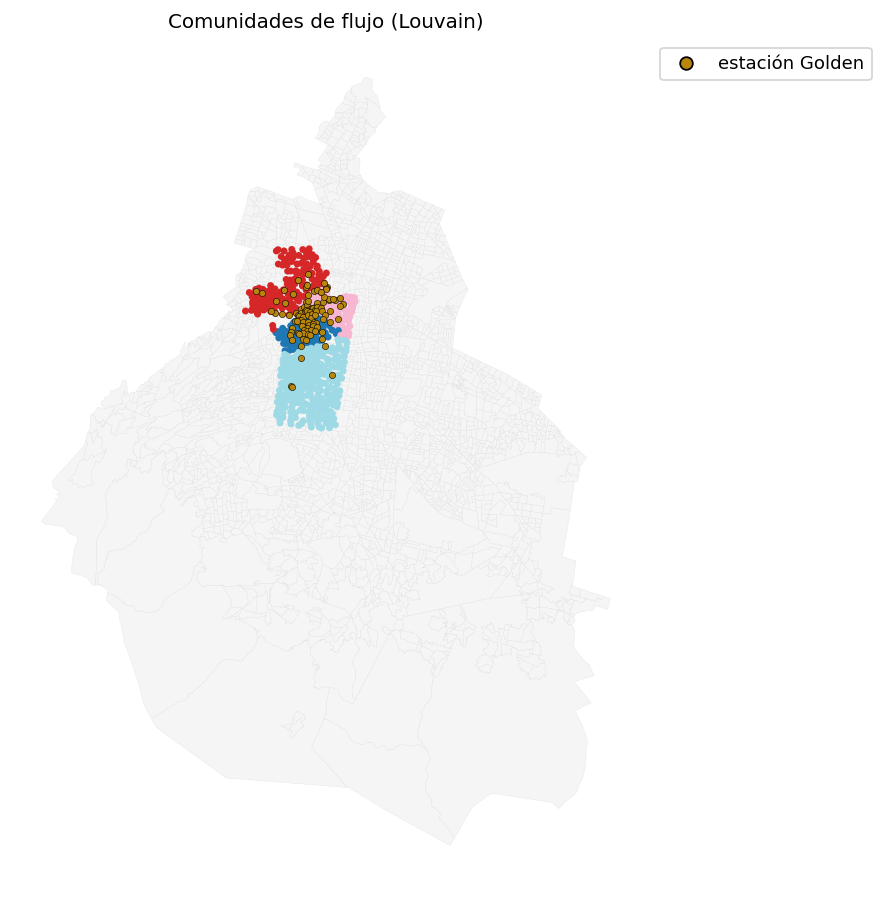

In [3]:
fl = report["flow"]
display(pd.Series(fl, name="valor").to_frame())
fcomm = result["flow"]["frame"]
st = stations.merge(fcomm[["ce_id", "community"]], on="ce_id",
                    how="left")
universe = data["frames"]["features"].to_crs(CONFIG["metric_crs"])
fig, ax = plt.subplots(figsize=(9, 7))
universe.plot(ax=ax, color="#F5F5F5", edgecolor="#DDDDDD",
              linewidth=0.15)
st.plot(ax=ax, column="community", cmap="tab20", markersize=8,
        legend=False)
st.loc[st.is_golden.astype(bool)].plot(ax=ax, color=GOLD,
                                      markersize=12,
                                      edgecolor="black",
                                      linewidth=0.3)
ax.legend(handles=[Line2D([0], [0], marker="o", color="w",
                          markerfacecolor=GOLD,
                          markeredgecolor="black", markersize=7,
                          label="estación Golden")],
          loc="upper left", bbox_to_anchor=(1.02, 1))
ax.set_axis_off(); ax.set_title("Comunidades de flujo (Louvain)")
plt.tight_layout(); plt.show()

## 3. Afinidad determinista al núcleo dorado

Sobre el grafo geométrico —estaciones existentes $\cup$ todos los
sitios candidatos, arista si distancia $\le$ enlace— se calculan
los **saltos al dorado más cercano** por BFS multifuente. La
afinidad de un sitio es

$$\text{afinidad}(s) = \frac{1}{1 + \text{saltos}_s}$$

dentro del componente conectado a la red, y $0$ fuera de él o sin
camino a una estación dorada —esos sitios no podrían anclarse de
todos modos—. Es **determinista, barata y exacta**: no hay
aproximación estocástica que validar.

**Nota obligatoria de alcance.** Como la afinidad es función
directa de los saltos a Golden, las métricas de cercanía a Golden
del portafolio —saltos máximos y mediana— quedan **optimizadas por
construcción** y NO constituyen evidencia independiente a favor de
este motor. La afinidad mide **proximidad estructural al núcleo
dorado**, no demanda observada.

,valor
definicion,1/(1+saltos a Golden) para sitios en el compon...
deterministica,True
n_sitios,1656
n_nodos_grafo,2333
n_aristas,10940
share_sitios_en_componente,1.0
n_estaciones_doradas,102


**Advertencia de alcance.** la afinidad es función directa de los saltos a Golden: las métricas de cercanía a Golden del portafolio (saltos máximos y mediana) quedan optimizadas POR CONSTRUCCIÓN y NO constituyen evidencia independiente a favor del Motor 3

/var/folders/xy/k1hx31l15bq5npxk8h1gcpwc0000gn/T/ipykernel_88015/3152365486.py:16: UserWarning: The GeoDataFrame you are attempting to plot is empty. Nothing has been displayed.
  sites_aff.loc[sites_aff.afinidad.eq(0)].plot(


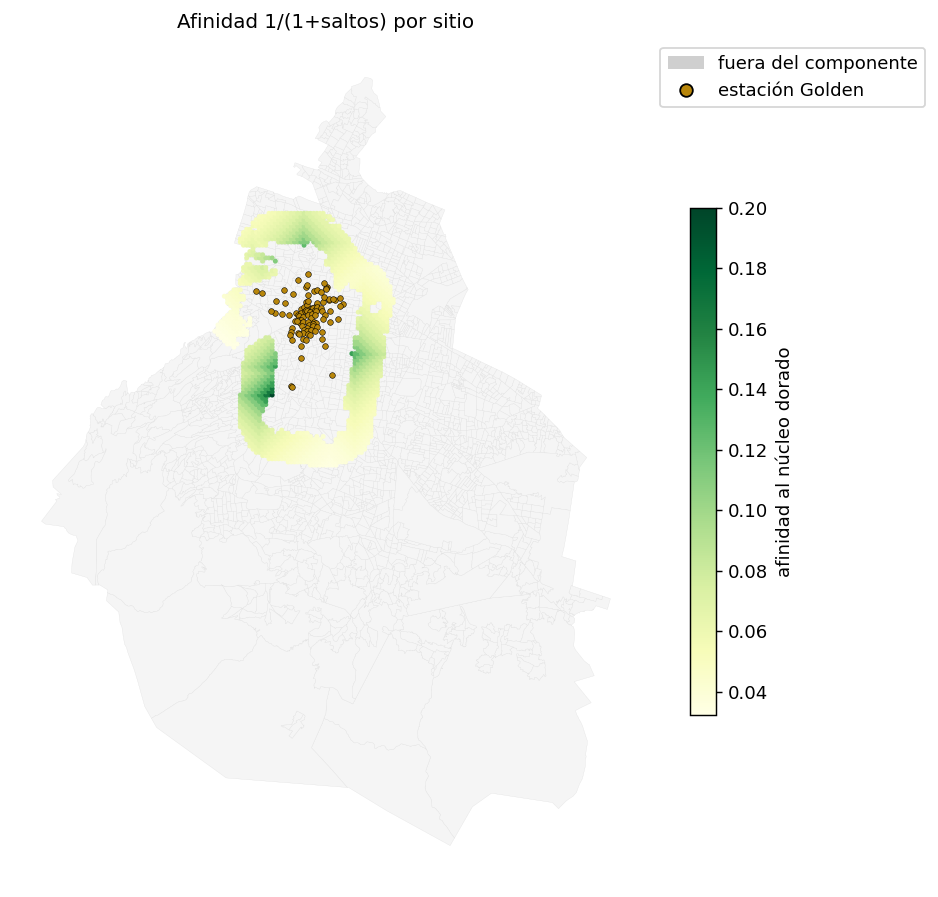

In [4]:
aff = report["affinity"]
display(pd.DataFrame([{
    "definicion": aff["definition"],
    "deterministica": aff["deterministic"],
    "n_sitios": aff["n_sites"],
    "n_nodos_grafo": aff["n_graph_nodes"],
    "n_aristas": aff["n_graph_edges"],
    "share_sitios_en_componente": aff["sites_in_component_share"],
    "n_estaciones_doradas": aff["n_golden_stations"],
}]).T.rename(columns={0: "valor"}))
display(Markdown(f"**Advertencia de alcance.** {aff['scope_warning']}"))
sites_aff = sites.assign(afinidad=result["affinity"])
fig, ax = plt.subplots(figsize=(9, 7))
universe.plot(ax=ax, color="#F5F5F5", edgecolor="#DDDDDD",
              linewidth=0.15)
sites_aff.loc[sites_aff.afinidad.eq(0)].plot(
    ax=ax, color="#CFCFCF", markersize=2, alpha=0.5)
sites_aff.loc[sites_aff.afinidad.gt(0)].plot(
    ax=ax, column="afinidad", cmap="YlGn", markersize=3,
    legend=True, legend_kwds={"label": "afinidad al núcleo dorado",
                            "shrink": 0.6})
stations.loc[stations.is_golden.astype(bool)].plot(
    ax=ax, color=GOLD, markersize=10, edgecolor="black",
    linewidth=0.3)
ax.legend(handles=[
    Patch(facecolor="#CFCFCF", label="fuera del componente"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor=GOLD,
           markeredgecolor="black", markersize=7,
           label="estación Golden")],
    loc="upper left", bbox_to_anchor=(1.02, 1))
ax.set_axis_off(); ax.set_title("Afinidad 1/(1+saltos) por sitio")
plt.tight_layout(); plt.show()

### Retiro de Node2Vec

Versiones anteriores de este cuaderno estimaban la afinidad con
**embeddings Node2Vec** sobre el grafo geométrico. Se retiran del
pipeline por decisión metodológica, con evidencia **HISTÓRICA** de la
publicación `v3-motor3-3` (analysis_id `69a83e61…05e7`, citada del
reporte —no recalculada—): la correlación de Spearman entre la
afinidad y la cercanía real al núcleo ($-$saltos al dorado) fue
prácticamente nula **bajo ambas definiciones** probadas:

| $q$ | centroide | dorado más cercano |
|---|---|---|
| 0.5 | −0.095 | −0.095 |
| 1.0 | −0.218 | −0.170 |
| 2.0 | −0.101 | −0.008 |

El núcleo dorado era además multimodal —razón de norma del centroide
0.735 y cosenos parejos dorado–dorado P10/P50/P90 = 0.14/0.56/0.88—,
lo que invalidaba el promedio como representante. Una afinidad
estructural que no ordena por cercanía al núcleo no aporta señal;
la implementación queda archivada en `node2vec_torch.py`, sin uso
en este cuaderno.

In [5]:
ret = report["node2vec_retired"]
display(pd.DataFrame(
    ret["historical_evidence_not_recomputed"][
        "spearman_affinity_vs_minus_hops_golden"]).T)
display(pd.Series({
    "esquema_historico": ret["historical_schema"],
    "analysis_id_historico": ret["historical_analysis_id"],
    "centroid_norm_ratio":
        ret["historical_evidence_not_recomputed"][
            "centroid_norm_ratio"],
    **{f"coseno_dorado_dorado_{k}": v for k, v in
       ret["historical_evidence_not_recomputed"][
           "golden_pairwise_cosine"].items()}},
    name="valor histórico (no recalculado)").to_frame())

,centroid,nearest_golden
q_0.5,-0.095,-0.095
q_1.0,-0.218,-0.170
q_2.0,-0.101,-0.008


,valor histórico (no recalculado)
esquema_historico,v3-motor3-3
analysis_id_historico,69a83e61b633b19f6b2914202c072d4b155a2cd59f397d...
centroid_norm_ratio,0.735
coseno_dorado_dorado_p10,0.14
coseno_dorado_dorado_p50,0.56
coseno_dorado_dorado_p90,0.88


## 4. Objetivo y factibilidad

La función objetivo mezcla cobertura poblacional nueva y afinidad
estructural con peso $w$:

$$f_w(S) = w\,\frac{\text{new\_pop}(S)}{P_{\text{norm}}}
+ (1-w)\,\frac{\sum_{s\in S}\text{affinity}_s}{B}$$

$P_{\text{norm}}$ es la suma de las $B$ mayores coberturas
individuales —cota superior submodular del contrato—. La
factibilidad la construye el decodificador de llaves aleatorias:
a lo sumo $B$ sitios, cada uno conectado a la red o a un sitio ya
elegido dentro de la distancia de enlace —crecimiento contiguo— y
separación mínima entre sitios. El verificador **independiente**
`is_feasible` del contrato valida cada portafolio publicado.

In [6]:
ctx = result["ctx"]
from V3.src.fe04_deployment import P_norm
display(pd.Series({
    "n_sitios": len(ctx["xy"]),
    "P_norm_B30_habitantes": P_norm(ctx, CONFIG["budget"]),
    "presupuesto_B": CONFIG["budget"],
    "peso_w_primario": CONFIG["primary_weight"],
    "share_sitios_en_componente":
        float(result["in_component"].mean()),
}, name="valor").to_frame())

,valor
n_sitios,1656.000000
P_norm_B30_habitantes,659672.587312
presupuesto_B,30.000000
peso_w_primario,0.500000
share_sitios_en_componente,1.000000


## 5. Greedy (principal) vs. GA (sensibilidad) vs. aleatorio

Tres métodos comparten el constructor de factibilidad: el **greedy**
de ganancia marginal de $f_w$ —motor prescriptivo principal—,
portafolios **aleatorios** por llaves uniformes y un **algoritmo
genético** sobre vectores de llaves —sin sembrar la solución greedy,
con elitismo fijo y semillas declaradas, conservado como
sensibilidad: el GA es una heurística sin garantía de óptimo—. Por
cada $(w, B)$ se reportan la $f$ del greedy, la mejor y la media del
GA, la brecha, el percentil del GA frente a la distribución
aleatoria, el Jaccard GA–greedy y los **tiempos de pared** medidos.

**Por qué greedy** —condicionado a lo medido: es determinista y
órdenes de magnitud más barato que el GA. La garantía $(1-1/e)$ de
la cobertura submodular **no aplica formalmente** bajo contigüidad y
espaciamiento —el buen desempeño aquí es un **hallazgo empírico, no
un teorema**—. Se reporta el resultado tal cual: si el GA gana en
algún peso o presupuesto se dice y se cuantifica la brecha; si la
diferencia es menor o igual que la variación entre semillas del GA,
se declara **empate**.

,weight,budget,greedy_f,ga_best_f,ga_mean_f,ga_std_f,ga_minus_greedy,ga_percentile_vs_random,jaccard_ga_greedy,jaccard_ga_pairwise,greedy_wall_s,ga_total_wall_s,ga_mean_wall_s_per_seed,verdict
0,0.00,30,0.137024,0.136098,0.135635,0.000378,-0.000926,1.0,0.875000,0.715219,0.02,171.5,57.172533,greedy
1,0.25,30,0.200107,0.198534,0.193284,0.003754,-0.001573,1.0,0.111111,0.323671,0.01,137.1,45.693002,empate (|brecha| <= std entre semillas)
2,0.50,30,0.289702,0.283511,0.276510,0.005309,-0.006191,1.0,0.132075,0.237889,0.02,257.0,51.399702,greedy
3,0.50,15,0.298166,0.288860,0.285666,0.004023,-0.009306,1.0,0.111111,0.208592,0.01,121.3,40.424693,greedy
4,0.50,50,0.280902,0.265145,0.260085,0.003617,-0.015757,1.0,0.190476,0.190926,0.03,264.8,88.281390,greedy
5,0.75,30,0.380034,0.370643,0.352997,0.020786,-0.009391,1.0,0.090909,0.213960,0.02,173.4,57.795840,empate (|brecha| <= std entre semillas)
6,1.00,30,0.470366,0.456551,0.447595,0.008477,-0.013815,1.0,0.153846,0.262709,0.02,177.5,59.178310,greedy


**Tiempos medidos.** Greedy total **0.1 s** en todas las corridas vs GA **21.7 min** (~186.1 s por semilla en promedio).

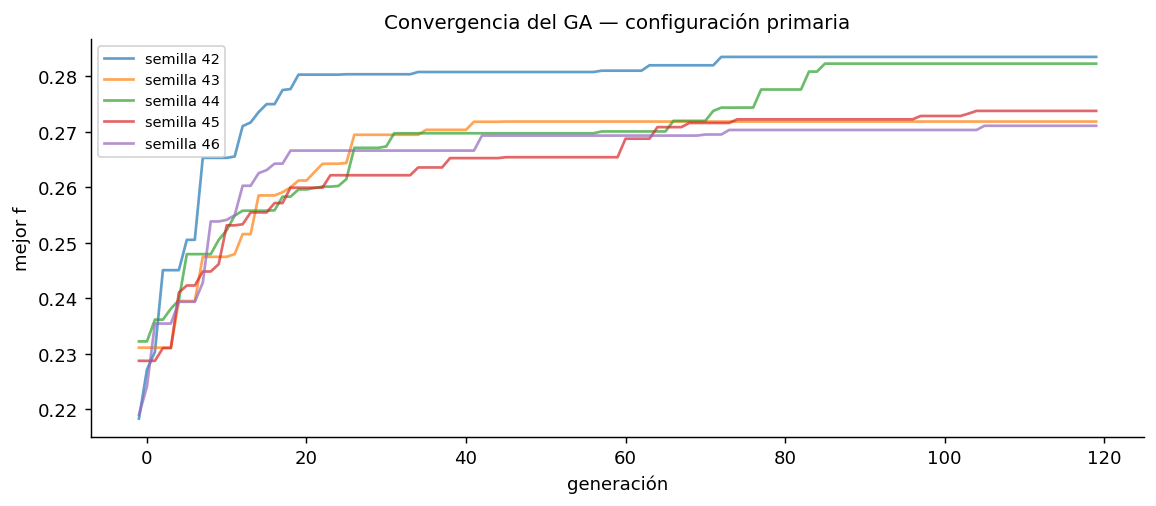

In [7]:
table = result["ga_greedy_table"]
display(table.assign(
    greedy_wall_s=table.greedy_wall_s.round(2),
    ga_total_wall_s=table.ga_total_wall_s.round(1)))
tm = report["timing"]
display(Markdown(
    f"**Tiempos medidos.** Greedy total "
    f"**{tm['greedy_total_wall_s']:.1f} s** en todas las corridas "
    f"vs GA **{tm['ga_total_wall_s']/60:.1f} min** "
    f"(~{tm['ga_mean_wall_s_per_seed']:.1f} s por semilla en "
    f"promedio)."))
hist = result["ga_history"]
fig, ax = plt.subplots(figsize=(9, 4))
prim = hist.loc[hist.weight.eq(CONFIG["primary_weight"])
                & hist.budget.eq(CONFIG["budget"])]
for seed, g in prim.groupby("seed"):
    ax.plot(g.generation, g.best, alpha=0.7, label=f"semilla {seed}")
ax.set(xlabel="generación", ylabel="mejor f",
       title="Convergencia del GA — configuración primaria")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 6. Portafolio primario (greedy) y sensibilidad GA

El portafolio primario es la corrida **greedy** en la configuración
primaria —determinista—; la mejor corrida del GA se publica como
sensibilidad `ga_best` con su Jaccard contra el primario. Todas las
métricas del portafolio son las del contrato común. La tabla por
AGEB responde «¿cuántas estaciones por AGEB?»: **condicional al
presupuesto y al objetivo**.

,valor
weight,0.5
budget,30
method,greedy
f,0.289702
ga_best,"{'seed': 42, 'f': 0.2835111661771723, 'jaccard..."
ga_better_than_greedy,False


,valor
n_selected,30
new_pop,310287.81353
new_pop_share,0.038941
redundancy,0.521415
n_agebs,28
stations_per_ageb,"{'1': 26, '2': 2, '3+': 0}"
max_hops_network,12
median_hops_golden,9.5
max_hops_golden,15
mean_dist_to_network_m,1700.284795


**Cambio del primario respecto a v3-motor3-3** (GA con afinidad Node2Vec)

,esquema_previo,motor_previo,new_pop_previo,agebs_previo,new_pop_actual,agebs_actual
0,v3-motor3-3,GA primario con afinidad Node2Vec,304459.536548,26,310287.81353,28


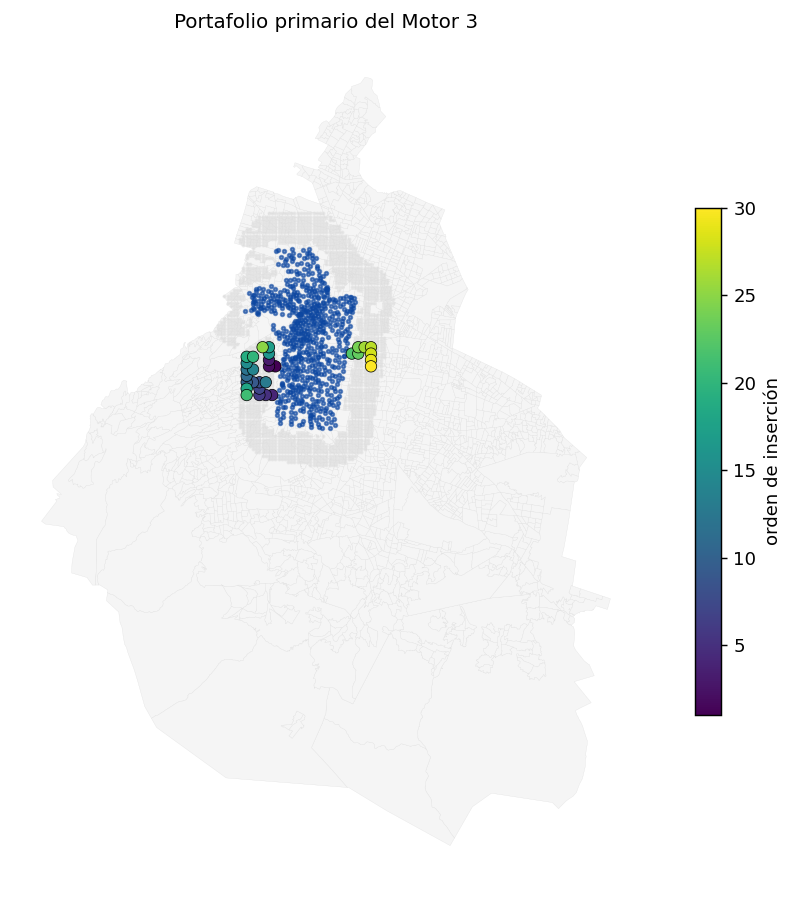

**Estaciones por AGEB** (portafolio primario)

,n_agebs
count,
1,26
2,2


,n_sitios
cvegeo,
0901000010135,2
0900600010255,2
0901000011773,1
0900600010575,1
0900600011126,1
0901000010012,1
0900600010236,1
0900600010382,1
0901400010153,1


In [8]:
pr = report["primary"]
display(pd.Series({k: v for k, v in pr.items()
                   if k not in ("metrics",
                                "primary_change_vs_v3_motor3_3")},
                  name="valor").to_frame())
display(pd.DataFrame([pr["metrics"]]).T.rename(columns={0: "valor"}))
display(Markdown("**Cambio del primario respecto a v3-motor3-3** "
                 "(GA con afinidad Node2Vec)"))
ch = pr["primary_change_vs_v3_motor3_3"]
display(pd.DataFrame([{
    "esquema_previo": ch["previous_schema"],
    "motor_previo": ch["previous_engine"],
    "new_pop_previo": ch["previous_B30"]["new_pop"],
    "agebs_previo": ch["previous_B30"]["n_agebs"],
    "new_pop_actual": ch["current_B30"]["new_pop"],
    "agebs_actual": ch["current_B30"]["n_agebs"]}]))
ports = result["portafolios"]
primary = ports.loc[ports.method.eq("greedy")
                    & ports.weight.eq(CONFIG["primary_weight"])
                    & ports.budget.eq(CONFIG["budget"])]
fig, ax = plt.subplots(figsize=(9, 7))
universe.plot(ax=ax, color="#F5F5F5", edgecolor="#DDDDDD",
              linewidth=0.15)
sites.plot(ax=ax, color="#DDDDDD", markersize=1.5, alpha=0.5)
stations.plot(ax=ax, color=BLUE, markersize=4, alpha=0.6)
primary.plot(ax=ax, column="order", cmap="viridis", markersize=40,
             edgecolor="black", linewidth=0.4, legend=True,
             legend_kwds={"label": "orden de inserción",
                          "shrink": 0.6})
ax.set_axis_off(); ax.set_title("Portafolio primario del Motor 3")
plt.tight_layout(); plt.show()
display(Markdown("**Estaciones por AGEB** (portafolio primario)"))
display(primary.cvegeo.value_counts().value_counts()
        .sort_index().rename("n_agebs").to_frame())
display(primary.cvegeo.value_counts().nlargest(15).rename(
    "n_sitios").to_frame())

## 7. Compromiso cobertura–afinidad y sensibilidad al presupuesto

La curva recorre $w$ de 0 —solo afinidad estructural— a 1 —solo
cobertura nueva—. La tensión es metodológicamente distinta a la de
los otros motores: la afinidad favorece sitios estructuralmente
cercanos al núcleo dorado, no entornos por perfil socioeconómico.
La sensibilidad al presupuesto repite las corridas declaradas.

,weight,budget,f,new_pop_norm,mean_affinity
0,0.00,30,0.137024,0.175851,0.137024
1,0.25,30,0.200107,0.466603,0.111275
2,0.50,30,0.289702,0.470366,0.109038
3,0.75,30,0.380034,0.470366,0.109038
4,1.00,30,0.470366,0.470366,0.109038


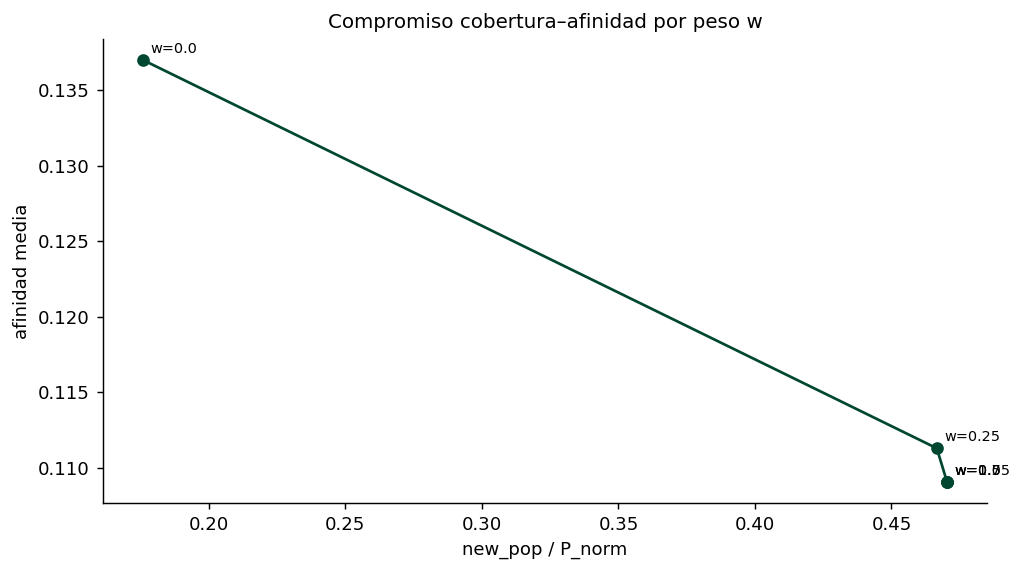

**Sensibilidad al presupuesto** (peso primario)

,weight,budget,greedy_f,ga_best_f,ga_mean_f,ga_std_f,ga_minus_greedy,ga_percentile_vs_random,jaccard_ga_greedy,jaccard_ga_pairwise,greedy_wall_s,ga_total_wall_s,ga_mean_wall_s_per_seed,verdict
2,0.5,30,0.289702,0.283511,0.276510,0.005309,-0.006191,1.0,0.132075,0.237889,0.016096,256.998508,51.399702,greedy
3,0.5,15,0.298166,0.288860,0.285666,0.004023,-0.009306,1.0,0.111111,0.208592,0.009143,121.274078,40.424693,greedy
4,0.5,50,0.280902,0.265145,0.260085,0.003617,-0.015757,1.0,0.190476,0.190926,0.030119,264.844171,88.281390,greedy


**Métricas por presupuesto** (contrato)

,n_selected,new_pop,new_pop_share,redundancy,n_agebs,stations_per_ageb,max_hops_network,median_hops_golden,max_hops_golden,mean_dist_to_network_m,mean_grado_escolar_prom_selected,mean_grado_escolar_prom_all_sites,mean_pct_viviendas_auto_selected,mean_pct_viviendas_auto_all_sites,out_of_domain_04_share
15,15,166731.061854,0.020925,0.502053,14,"{'1': 13, '2': 1, '3+': 0}",10,8.0,13,1675.230251,11.632,12.234022,0.44575,0.521034,0.733333
30,30,310287.81353,0.038941,0.521415,28,"{'1': 26, '2': 2, '3+': 0}",12,9.5,15,1700.284795,11.639,12.234022,0.437803,0.521034,0.566667
50,50,481553.561453,0.060435,0.576122,46,"{'1': 42, '2': 4, '3+': 0}",15,11.0,20,1786.448195,11.5692,12.234022,0.434803,0.521034,0.4


In [9]:
display(result["tradeoff"])
fig, ax = plt.subplots(figsize=(8, 4.5))
tr = result["tradeoff"]
ax.plot(tr.new_pop_norm, tr.mean_affinity, "-o", color=GREEN)
for _, r in tr.iterrows():
    ax.annotate(f"w={r.weight}", (r.new_pop_norm, r.mean_affinity),
                fontsize=8, xytext=(4, 4),
                textcoords="offset points")
ax.set(xlabel="new_pop / P_norm", ylabel="afinidad media",
       title="Compromiso cobertura–afinidad por peso w")
plt.tight_layout(); plt.show()
display(Markdown("**Sensibilidad al presupuesto** (peso primario)"))
display(table.loc[table.weight.eq(CONFIG["primary_weight"])])
display(Markdown("**Métricas por presupuesto** (contrato)"))
display(pd.DataFrame(
    report["portfolios"]["budget_sensitivity"]).T)

## 8. Límites y publicación

- La afinidad $1/(1+	ext{saltos})$ mide **proximidad estructural**
  al núcleo dorado, no demanda observada ni preferencia de usuarios.
  Al ser función directa de los saltos a Golden, las métricas de
  cercanía a Golden del portafolio quedan **optimizadas por
  construcción**: no son evidencia independiente a favor de este
  motor.
- La interpolación areal y la captura de 500 m son **supuestos**, no
  demanda observada.
- No hay red vial, costos, factibilidad de terreno ni validación de
  campo.
- La superposición de capturas no prueba canibalización.
- El greedy es el motor prescriptivo principal por determinismo y
  costo medido; el GA es una heurística sin garantía de optimalidad
  publicada solo como sensibilidad `ga_best`. La garantía $(1-1/e)$
  de la cobertura submódular no aplica formalmente bajo nuestras
  restricciones de contigüidad y espaciamiento.
- Node2Vec quedó **retirado del pipeline** por decisión
  metodológica, con evidencia histórica citada de la publicación
  `v3-motor3-3`; el código queda archivado, sin uso.

In [10]:
display(pd.DataFrame({"pending_validation":
                      report["pending_validation"]}))
report_path = stage_results(V3_DIR, data, result)
display(Markdown("**Cierre.** Portafolio prescriptivo autónomo del "
                 "Motor 3 publicado con verificación de integridad."))
display(JSON({"m3_report_path": report_path.relative_to(V3_DIR).as_posix()}))

,pending_validation
0,Affinity is a deterministic function of hops t...
1,Structural affinity is proximity to the golden...
2,Areal interpolation and 500 m catchments are a...
3,"No street network, cost, or field validation"
4,The GA is a heuristic without optimality guara...


**Cierre.** Portafolio prescriptivo autónomo del Motor 3 publicado con verificación de integridad.

<IPython.core.display.JSON object>